In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [32]:
stock_data = pd.read_csv("../data/apple_stock_processed.csv", index_col="Date", parse_dates=True)

stock_data.head()

,Close,High,Low,Open,Volume,Lag_1,Lag_2,Lag_3,MA_5,MA_10,Daily_Return,Volatility_5,Target
Date,,,,,,,,,,,,,
2020-01-15,74.980614,75.982475,74.549522,75.103440,121923600,75.303337,76.334068,74.737366,75.184834,73.696977,-0.004286,0.015546,75.919853
2020-01-16,75.919853,76.030641,75.161234,75.522482,108829200,74.980614,75.303337,76.334068,75.455048,74.055574,0.012526,0.013709,76.760353
2020-01-17,76.760353,76.762756,75.862047,76.167901,137816400,75.919853,74.980614,75.303337,75.859645,74.568546,0.011071,0.014044,76.240150
2020-01-21,76.240150,76.830184,76.102875,76.389465,110843200,76.760353,75.919853,74.980614,75.840862,74.972421,-0.006777,0.011466,76.512299
2020-01-22,76.512299,77.063798,76.418371,76.724224,101832400,76.240150,76.760353,75.919853,76.082654,75.437467,0.003570,0.008727,76.880775


In [33]:
# Features
X = stock_data.drop("Target", axis=1)

# Target
y = stock_data["Target"]

In [34]:
    # Features
X = stock_data.drop("Target", axis=1)

    # Target
y = stock_data["Target"]

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (1497, 12)
Shape of y: (1497,)


In [35]:
# ✅ Correct
y = stock_data["Target"]

Train-Test Split
Now comes a very important question.
Normally, in machine learning we write:

In [36]:
# Find the split index (80% training)
split_index = int(len(stock_data) * 0.8)

# Training data
X_train = X[:split_index]
y_train = y[:split_index]

# Testing data
X_test = X[split_index:]
y_test = y[split_index:]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1197, 12)
Testing data: (300, 12)


In [37]:
# Find the split index (80% of the data)
split_index = int(len(stock_data) * 0.8)

# Split the features
X_train = X[:split_index]
X_test = X[split_index:]

# Split the target
y_train = y[:split_index]
y_test = y[split_index:]

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1197, 12)
X_test shape: (300, 12)
y_train shape: (1197,)
y_test shape: (300,)


model building

1.LINEAR REGRESSION

In [38]:
from sklearn.linear_model import LinearRegression

In [39]:
model = LinearRegression()

In [40]:
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


Step 1: Make Predictions

In [41]:
# Make predictions
predictions = model.predict(X_test)

print(predictions[:10])

[230.41261419 231.96615223 232.49794609 232.76040086 231.92980259
 230.63595607 230.38175061 230.9597554  231.13825373 230.56462494]


Compare Actual vs Predicted

In [42]:
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
print("Predictions shape:", predictions.shape)

print(type(y_test))

X_test shape: (300, 12)
y_test shape: (300,)
Predictions shape: (300,)
<class 'pandas.core.series.Series'>


In [43]:
print("y_test shape:", y_test.shape)
print("predictions shape:", predictions.shape)
print(type(y_test))

y_test shape: (300,)
predictions shape: (300,)
<class 'pandas.core.series.Series'>


In [44]:
print(type(y))
print(type(y_train))
print(type(y_test))

print(y.shape)
print(y_train.shape)
print(y_test.shape)

<class 'pandas.core.series.Series'>
<class 'pandas.core.series.Series'>
<class 'pandas.core.series.Series'>
(1497,)
(1197,)
(300,)


In [45]:
print(type(predictions))
print(predictions.shape)

<class 'numpy.ndarray'>
(300,)


In [46]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": predictions
})

comparison.head(10)

,Actual,Predicted
Date,,
2024-10-17,233.251465,230.412614
2024-10-18,234.720459,231.966152
2024-10-21,234.105087,232.497946
2024-10-22,229.043015,232.760401
2024-10-23,228.854446,231.929803
2024-10-24,229.688217,230.635956
2024-10-25,231.663376,230.381751
2024-10-28,231.931381,230.959755
2024-10-29,228.387939,231.138254


In [47]:
print(type(predictions))
print(predictions.shape)

<class 'numpy.ndarray'>
(300,)


In [48]:
print(type(y_test))
print(y_test.shape)

print(type(predictions))
print(predictions.shape)

print(y_test.head())
print(predictions[:5])

<class 'pandas.core.series.Series'>
(300,)
<class 'numpy.ndarray'>
(300,)
Date
2024-10-17    233.251465
2024-10-18    234.720459
2024-10-21    234.105087
2024-10-22    229.043015
2024-10-23    228.854446
Name: Target, dtype: float64
[230.41261419 231.96615223 232.49794609 232.76040086 231.92980259]


In [49]:
comparison = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": predictions
})

comparison.head(10)

,Actual,Predicted
0,233.251465,230.412614
1,234.720459,231.966152
2,234.105087,232.497946
3,229.043015,232.760401
4,228.854446,231.929803
5,229.688217,230.635956
6,231.663376,230.381751
7,231.931381,230.959755
8,228.387939,231.138254
9,224.229126,230.564625


In [50]:
y_test.to_numpy()

array([233.25146484, 234.72045898, 234.10508728, 229.04301453,
       228.85444641, 229.68821716, 231.66337585, 231.93138123,
       228.38793945, 224.22912598, 221.25144958, 220.35812378,
       221.78741455, 221.06283569, 225.78742981, 225.51914978,
       222.80647278, 222.80647278, 223.69082642, 226.77114868,
       223.57159424, 226.57241821, 226.83074951, 227.54618835,
       227.06925964, 228.41067505, 231.39163208, 233.56771851,
       233.43852234, 235.82331848, 238.06896973, 241.10952759,
       241.46725464, 241.49703979, 241.29830933, 245.1835022 ,
       246.19702148, 244.92515564, 246.38581848, 246.55473328,
       249.44625854, 251.87077332, 246.47525024, 248.20419312,
       252.87437439, 253.64944458, 256.56082153, 257.37557983,
       253.96737671, 250.59890747, 248.83018494, 242.30192566,
       241.81504822, 243.44459534, 240.67234802, 241.15922546,
       235.34637451, 232.91191101, 231.79902649, 236.35986328,
       226.81088257, 228.51998901, 221.2265625 , 222.40

Step 1: Import Evaluation Metrics

In [51]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [52]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [53]:
mae = mean_absolute_error(y_test, predictions)

print("Mean Absolute Error (MAE):", mae)

Mean Absolute Error (MAE): 3.8766364201958927


In [54]:
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("Root Mean Squared Error (RMSE):", rmse)

Root Mean Squared Error (RMSE): 5.446651662625362


In [55]:
r2 = r2_score(y_test, predictions)

print("R² Score:", r2)

R² Score: 0.9509181467704543


In [56]:
print("=" * 40)
print("Linear Regression Results")
print("=" * 40)

print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

Linear Regression Results
MAE  : 3.8766
RMSE : 5.4467
R²   : 0.9509


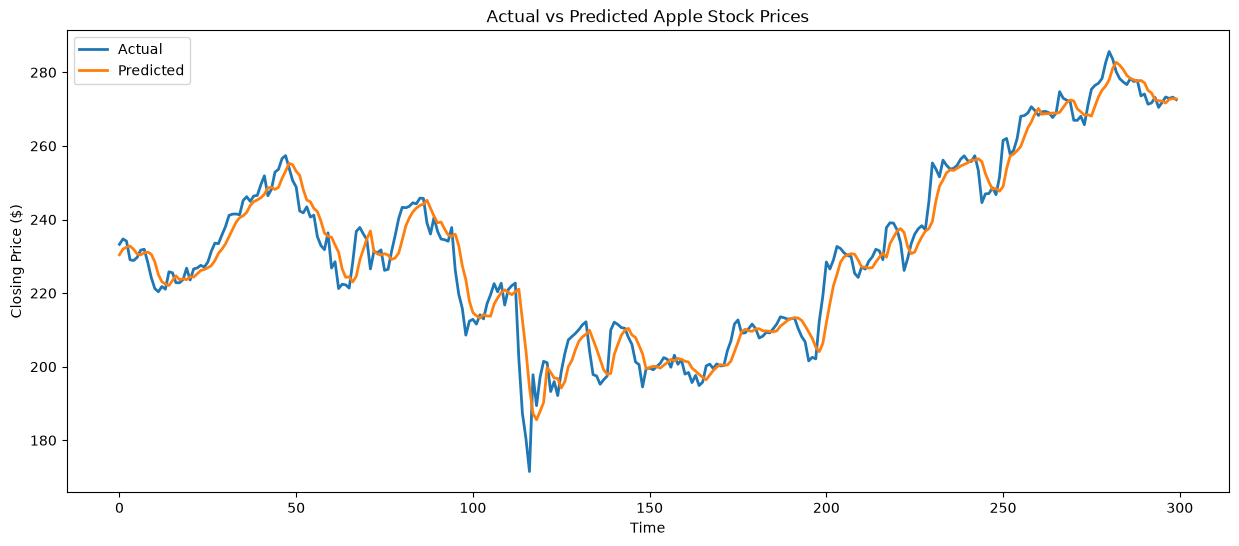

In [57]:
plt.figure(figsize=(15, 6))

plt.plot(y_test.values, label="Actual", linewidth=2)
plt.plot(predictions, label="Predicted", linewidth=2)

plt.title("Actual vs Predicted Apple Stock Prices")
plt.xlabel("Time")
plt.ylabel("Closing Price ($)")
plt.legend()

plt.show()

2.RANDOM FOREST


In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [59]:
stock_data = pd.read_csv(
    "../data/apple_stock_processed.csv",
    index_col="Date",
    parse_dates=True
)

stock_data.head()

,Close,High,Low,Open,Volume,Lag_1,Lag_2,Lag_3,MA_5,MA_10,Daily_Return,Volatility_5,Target
Date,,,,,,,,,,,,,
2020-01-15,74.980614,75.982475,74.549522,75.103440,121923600,75.303337,76.334068,74.737366,75.184834,73.696977,-0.004286,0.015546,75.919853
2020-01-16,75.919853,76.030641,75.161234,75.522482,108829200,74.980614,75.303337,76.334068,75.455048,74.055574,0.012526,0.013709,76.760353
2020-01-17,76.760353,76.762756,75.862047,76.167901,137816400,75.919853,74.980614,75.303337,75.859645,74.568546,0.011071,0.014044,76.240150
2020-01-21,76.240150,76.830184,76.102875,76.389465,110843200,76.760353,75.919853,74.980614,75.840862,74.972421,-0.006777,0.011466,76.512299
2020-01-22,76.512299,77.063798,76.418371,76.724224,101832400,76.240150,76.760353,75.919853,76.082654,75.437467,0.003570,0.008727,76.880775


In [60]:
X = stock_data.drop("Target", axis=1)
y = stock_data["Target"]

In [61]:
split_index = int(len(stock_data) * 0.8)

X_train = X[:split_index]
X_test = X[split_index:]

y_train = y[:split_index]
y_test = y[split_index:]

In [62]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

In [63]:
rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [64]:
rf_predictions = rf_model.predict(X_test)

In [65]:
mae = mean_absolute_error(y_test, rf_predictions)
rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
r2 = r2_score(y_test, rf_predictions)

print("Random Forest Results")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

Random Forest Results
MAE  : 13.5038
RMSE : 20.0086
R²   : 0.3376


In [66]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "RandomForest": rf_predictions
})

comparison.head(10)

,Actual,RandomForest
Date,,
2024-10-17,233.251465,229.537776
2024-10-18,234.720459,230.282171
2024-10-21,234.105087,229.686234
2024-10-22,229.043015,229.257515
2024-10-23,228.854446,228.797897
2024-10-24,229.688217,228.965021
2024-10-25,231.663376,229.441980
2024-10-28,231.931381,229.825918
2024-10-29,228.387939,229.565339


In [67]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
0,Close,0.649282
2,Low,0.123808
1,High,0.096774
3,Open,0.054071
8,MA_5,0.026914
6,Lag_2,0.016310
9,MA_10,0.015133
5,Lag_1,0.014239
7,Lag_3,0.002087
4,Volume,0.000527


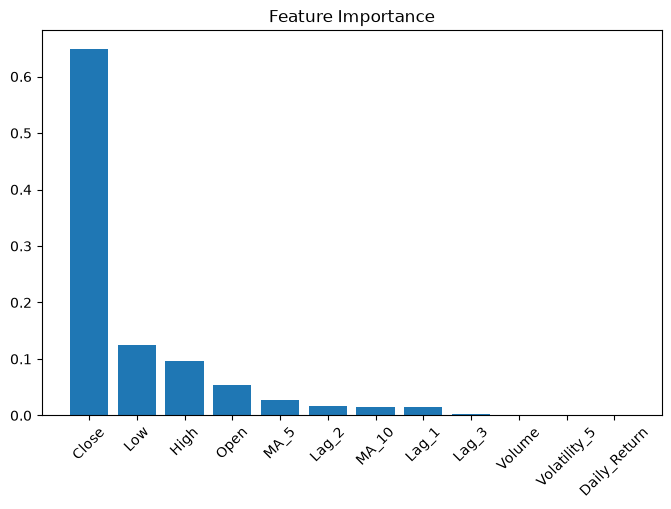

In [68]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.bar(feature_importance["Feature"],
        feature_importance["Importance"])
plt.xticks(rotation=45)
plt.title("Feature Importance")
plt.show()

Unlike Random Forest:
Random Forest builds trees independently.
XGBoost builds one tree, measures its mistakes, then builds the next tree to correct those mistakes.

3.XGBOOST (Extreme Gradient Boosting) is an ensemble learning algorithm that builds many decision trees sequentially.

In [69]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [70]:
from xgboost import XGBRegressor

In [71]:
xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42
)

In [72]:
xgb_model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [73]:
xgb_predictions = xgb_model.predict(X_test)

In [74]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, xgb_predictions)
rmse = np.sqrt(mean_squared_error(y_test, xgb_predictions))
r2 = r2_score(y_test, xgb_predictions)

print("XGBoost Results")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

XGBoost Results
MAE  : 14.3535
RMSE : 21.2573
R²   : 0.2524


In [75]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": xgb_predictions
})

comparison.head(10)



,Actual,Predicted
Date,,
2024-10-17,233.251465,228.559067
2024-10-18,234.720459,229.129532
2024-10-21,234.105087,228.368118
2024-10-22,229.043015,227.305740
2024-10-23,228.854446,227.994446
2024-10-24,229.688217,228.696976
2024-10-25,231.663376,228.548813
2024-10-28,231.931381,228.694214
2024-10-29,228.387939,228.582855


In [76]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": xgb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
0,Close,0.487214
1,High,0.175545
5,Lag_1,0.162296
2,Low,0.100249
3,Open,0.033021
8,MA_5,0.020787
6,Lag_2,0.012091
9,MA_10,0.005632
7,Lag_3,0.001909
10,Daily_Return,0.000477


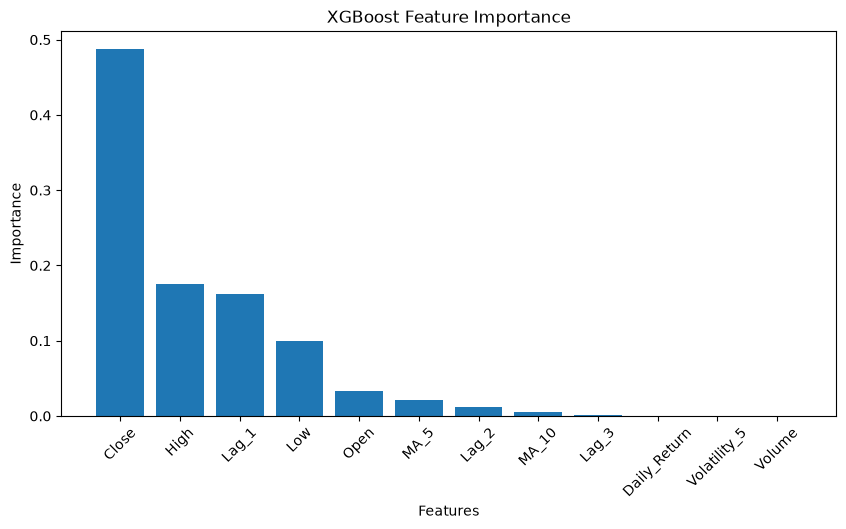

In [77]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.bar(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xticks(rotation=45)
plt.title("XGBoost Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")

plt.show()

MODEL COMPARISON TABLE 

In [78]:
comparison_df = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "XGBoost"
    ],
    
    "MAE": [
        3.8766,
        13.5038,
        14.3535
    ],
    
    "RMSE": [
        5.4467,
        20.0086,
        21.2573
    ],
    
    "R² Score": [
        0.9509,
        0.3376,
        0.2524
    ]
})

comparison_df

,Model,MAE,RMSE,R² Score
0,Linear Regression,3.8766,5.4467,0.9509
1,Random Forest,13.5038,20.0086,0.3376
2,XGBoost,14.3535,21.2573,0.2524


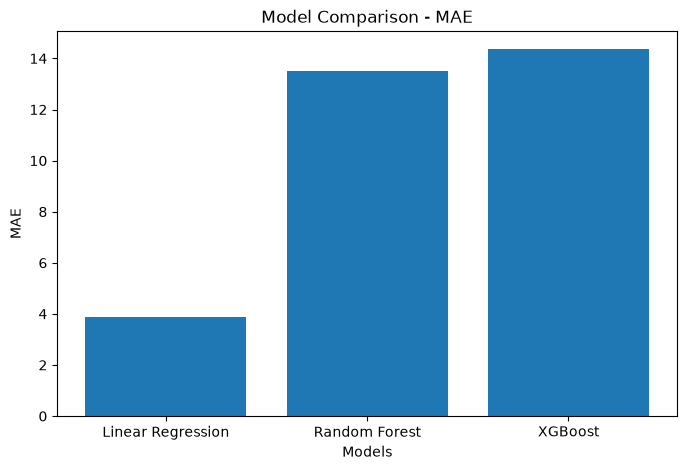

In [79]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.bar(
    comparison_df["Model"],
    comparison_df["MAE"]
)

plt.title("Model Comparison - MAE")
plt.xlabel("Models")
plt.ylabel("MAE")

plt.show()

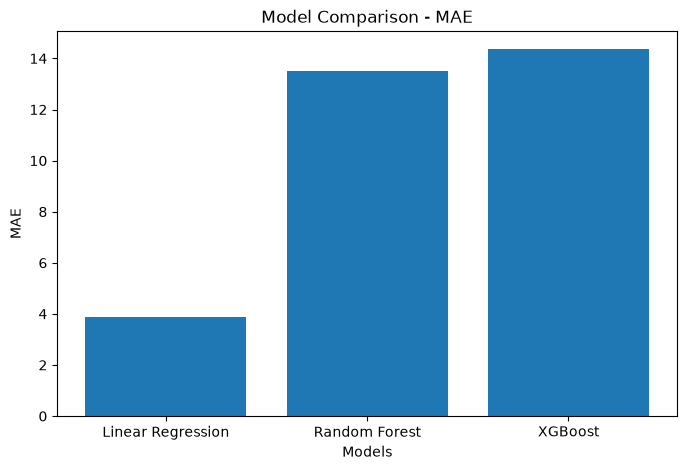

In [80]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.bar(
    comparison_df["Model"],
    comparison_df["MAE"]
)

plt.title("Model Comparison - MAE")
plt.xlabel("Models")
plt.ylabel("MAE")

plt.show()

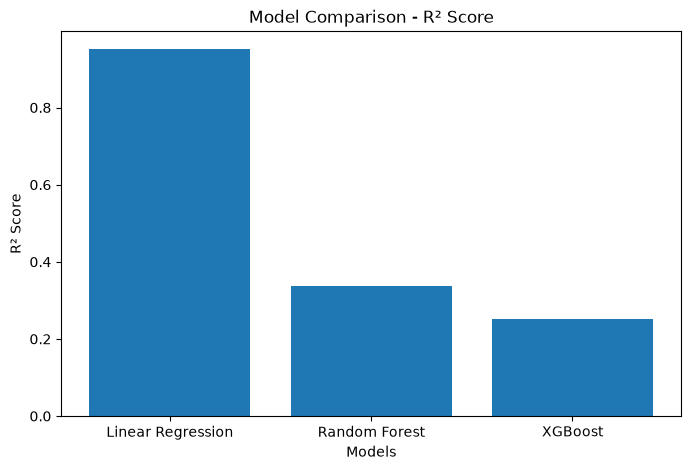

In [81]:
plt.figure(figsize=(8,5))

plt.bar(
    comparison_df["Model"],
    comparison_df["R² Score"]
)

plt.title("Model Comparison - R² Score")
plt.xlabel("Models")
plt.ylabel("R² Score")

plt.show()

In [82]:
best_model = comparison_df.loc[
    comparison_df["R² Score"].idxmax()
]

best_model

Model       Linear Regression
MAE                    3.8766
RMSE                   5.4467
R² Score               0.9509
Name: 0, dtype: object

## Analysis

The three machine learning models were evaluated using MAE, RMSE, and R² Score.

Among the evaluated models, Linear Regression achieved the best performance with the lowest prediction error and the highest R² score. This indicates that the relationship between the selected features and the target variable is captured effectively by a linear model.

Although Random Forest and XGBoost are powerful ensemble learning algorithms, they did not outperform Linear Regression on the current dataset. This suggests that the engineered features exhibit a predominantly linear relationship with the target, making Linear Regression a more suitable choice in this case.

Further improvements may be achieved by incorporating additional technical indicators, performing hyperparameter tuning, and using time-series-specific validation techniques.

MODEL TRAINING FOR THE VERSION-2


In [83]:
import pandas as pd
import numpy as np

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib

In [84]:
stock_data = pd.read_csv("../data/apple_stock_feature_engineered.csv")

stock_data.head()

,Date,Close,High,Low,Open,Volume,Lag_1,Lag_2,Lag_3,MA_5,...,MACD,Signal_Line,MACD_Histogram,BB_Middle,BB_Upper,BB_Lower,TR,ATR_14,Momentum_10,ROC_10
0,2020-02-12,78.987221,78.992046,77.603976,77.603976,113730400,77.154976,77.623299,77.256371,77.868564,...,0.663154,0.485660,0.177494,76.670024,79.298546,74.041503,1.837070,2.066748,0.875793,1.121210
1,2020-02-13,78.424736,78.750632,78.057805,78.260583,94747600,78.987221,77.154976,77.623299,77.889320,...,0.712097,0.530947,0.181149,76.842231,79.455966,74.228495,0.929415,2.033190,0.426483,0.546786
2,2020-02-14,78.444069,78.692714,77.937120,78.393369,80113600,78.424736,78.987221,77.154976,78.126860,...,0.743869,0.573532,0.170337,76.968441,79.637826,74.299056,0.755594,1.856134,3.904182,5.237709
3,2020-02-18,77.007706,77.188758,75.947941,76.128994,152531200,78.444069,78.424736,78.987221,78.003741,...,0.645703,0.587966,0.057737,76.980809,79.648426,74.313192,2.496128,1.871869,2.672516,3.595223
4,2020-02-19,78.123009,78.352345,77.249129,77.249129,93984000,77.007706,78.444069,78.424736,78.197348,...,0.650404,0.600454,0.049951,77.074952,79.765311,74.384593,1.344639,1.793138,1.333725,1.736863


In [85]:
selected_features = [
    "Close",
    "High",
    "Low",
    "Open",
    "Volume",
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "MA_5",
    "MA_10",
    "Daily_Return",
    "Volatility_5",
    "EMA_12",
    "EMA_26",
    "RSI_14",
    "MACD",
    "Signal_Line",
    "MACD_Histogram",
    "BB_Middle",
    "BB_Upper",
    "BB_Lower",
    "TR",
    "ATR_14",
    "Momentum_10",
    "ROC_10"
]

X = stock_data[selected_features]
y = stock_data["Target"]

In [86]:
from sklearn.model_selection import train_test_split
split_index = int(len(stock_data) * 0.8)

X_train = X[:split_index]
X_test = X[split_index:]

y_train = y[:split_index]
y_test = y[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 1182
Testing samples: 296


In [87]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](25,)","[ 0.07, 0.07, 0.07,..., 0. , 0. ,-0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](25,)","['Close','High','Low',...,'ATR_14','Momentum_10','ROC_10']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.84
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,25
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [88]:
y_pred = linear_model.predict(X_test)

In [89]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

MAE  : 4.6727
RMSE : 6.3107
R²   : 0.9350


rectifying the version 2 

In [90]:
selected_features = [
    "Close",
    "High",
    "Low",
    "Open",
    "EMA_26",
    "BB_Middle",
    "Lag_1",
    "Lag_2",
    "MA_5",
    "MA_10"
]

X = stock_data[selected_features]
y = stock_data["Target"]

In [91]:
split_index = int(len(stock_data) * 0.8)

X_train = X[:split_index]
X_test = X[split_index:]

y_train = y[:split_index]
y_test = y[split_index:]

In [92]:
linear_model_selected = LinearRegression()

linear_model_selected.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[ 0.75, 0.14, 0.34,...,-0.01, 0.07,-0.02]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](10,)","['Close','High','Low',...,'Lag_2','MA_5','MA_10']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.6077
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(10)


In [93]:
y_pred_selected = linear_model_selected.predict(X_test)

In [94]:
mae = mean_absolute_error(y_test, y_pred_selected)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_selected))
r2 = r2_score(y_test, y_pred_selected)

print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

MAE  : 2.7482
RMSE : 4.1431
R²   : 0.9720


In [96]:
joblib.dump(linear_model_selected, "../models/linear_regression_selected.pkl")

print("Model saved successfully!")

Model saved successfully!
